        # Cognitive Science (1204 427) — Lab 07
        ## Mental Rotation

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        Mental Rotation ศึกษาการแปลงภาพในใจ โดย Reaction Time มักเพิ่มขึ้นตาม Angular Disparity ซึ่งตีความได้ว่าการหมุนภาพในใจอาจเกิดอย่างต่อเนื่อง

        ### วัตถุประสงค์

        ประมาณความสัมพันธ์ระหว่างมุมหมุนกับ RT วิเคราะห์ Accuracy และอธิบายความหมายของ Regression Slope

        ### งานที่ต้องทำ

        1. สร้างข้อมูล 32 คนในมุม 0–180 องศา
2. วิเคราะห์ RT เฉพาะ Trial ที่ตอบถูก
3. Fit Linear Regression ระหว่าง Angle และ RT
4. เปรียบเทียบ Same กับ Mirror Stimuli
5. Required Extension: ทดสอบโมเดล Quadratic และเปรียบเทียบ RMSE

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

rng = np.random.default_rng(seed + 70)
angles = [0, 45, 90, 135, 180]
rows = []
for participant in range(1, 33):
    baseline = rng.normal(520, 55)
    slope = rng.normal(4.2, 0.6)  # ms per degree
    for stimulus in ["Same", "Mirror"]:
        for angle in angles:
            for trial in range(1, 7):
                extra = 80 if stimulus == "Mirror" else 0
                rt = rng.normal(baseline + slope * angle + extra, 90)
                p_correct = np.clip(0.97 - 0.0014 * angle - (0.03 if stimulus == "Mirror" else 0), 0.55, 0.99)
                correct = rng.binomial(1, p_correct)
                rows.append([participant, stimulus, angle, trial, rt, correct])
rotation_df = pd.DataFrame(rows, columns=["participant", "stimulus", "angle", "trial", "rt", "correct"])
display(rotation_df.head())


,participant,stimulus,angle,trial,rt,correct
0,1,Same,0,1,591.963276,1
1,1,Same,0,2,503.243109,1
2,1,Same,0,3,326.160041,1
3,1,Same,0,4,399.296959,1
4,1,Same,0,5,604.488859,1


stimulus,Mirror,Same
angle,,
0,608.80,532.60
45,788.53,715.72
90,975.39,892.70
135,1169.97,1082.26
180,1343.94,1277.56


stimulus,Mirror,Same
angle,,
0,0.964,0.984
45,0.854,0.885
90,0.802,0.828
135,0.745,0.771
180,0.719,0.755


Slope=4.118 ms/degree, intercept=567.45, R²=1.000, p=0.000000


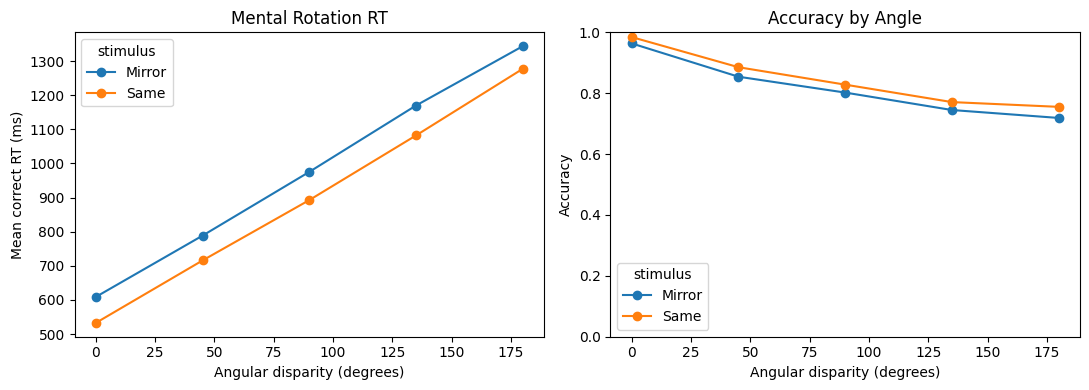

In [3]:
clean = rotation_df[(rotation_df.correct == 1) & rotation_df.rt.between(200, 2500)]
summary = clean.groupby(["stimulus", "angle"])["rt"].mean().unstack(0)
accuracy = rotation_df.groupby(["stimulus", "angle"])["correct"].mean().unstack(0)
display(summary.round(2)); display(accuracy.round(3))

mean_by_angle = clean.groupby("angle")["rt"].mean().reset_index()
fit = linregress(mean_by_angle["angle"], mean_by_angle["rt"])
print(f"Slope={fit.slope:.3f} ms/degree, intercept={fit.intercept:.2f}, R²={fit.rvalue**2:.3f}, p={fit.pvalue:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary.plot(marker="o", ax=axes[0]); axes[0].set_ylabel("Mean correct RT (ms)"); axes[0].set_title("Mental Rotation RT")
accuracy.plot(marker="o", ax=axes[1]); axes[1].set_ylabel("Accuracy"); axes[1].set_ylim(0, 1); axes[1].set_title("Accuracy by Angle")
for ax in axes: ax.set_xlabel("Angular disparity (degrees)")
plt.tight_layout(); plt.show()


## Required Extension

Fit Polynomial Degree 2 กับ Mean RT แล้วเปรียบเทียบ RMSE กับ Linear Model พร้อมอธิบายว่าความซับซ้อนที่เพิ่มขึ้นคุ้มค่าหรือไม่


Linear RMSE    = 2.726 ms
Quadratic RMSE = 1.839 ms


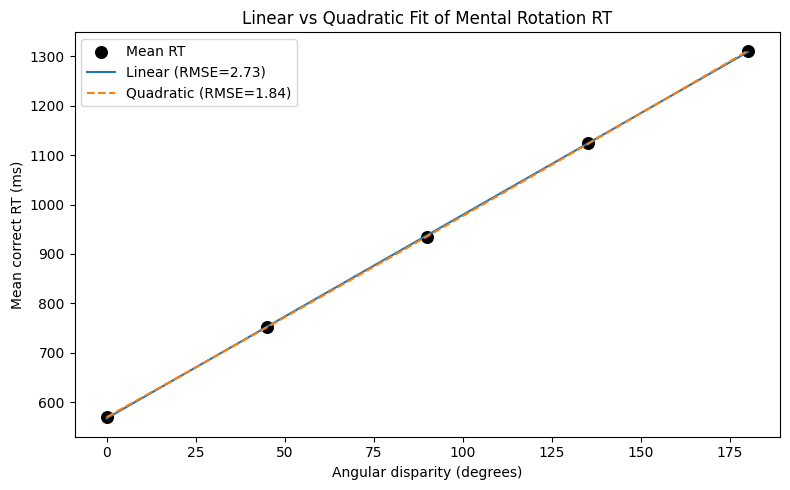

In [4]:
# ===== Required Extension: Fit Quadratic แล้วเทียบ RMSE กับ Linear =====
linear_coef = np.polyfit(mean_by_angle["angle"], mean_by_angle["rt"], 1)
linear_pred = np.polyval(linear_coef, mean_by_angle["angle"])
linear_rmse = np.sqrt(np.mean((mean_by_angle["rt"] - linear_pred) ** 2))

quad_coef = np.polyfit(mean_by_angle["angle"], mean_by_angle["rt"], 2)
quad_pred = np.polyval(quad_coef, mean_by_angle["angle"])
quad_rmse = np.sqrt(np.mean((mean_by_angle["rt"] - quad_pred) ** 2))

print(f"Linear RMSE    = {linear_rmse:.3f} ms")
print(f"Quadratic RMSE = {quad_rmse:.3f} ms")

grid = np.linspace(0, 180, 100)
plt.figure(figsize=(8, 5))
plt.scatter(mean_by_angle["angle"], mean_by_angle["rt"], s=70, color="black", label="Mean RT")
plt.plot(grid, np.polyval(linear_coef, grid), label=f"Linear (RMSE={linear_rmse:.2f})")
plt.plot(grid, np.polyval(quad_coef, grid), "--", label=f"Quadratic (RMSE={quad_rmse:.2f})")
plt.xlabel("Angular disparity (degrees)")
plt.ylabel("Mean correct RT (ms)")
plt.title("Linear vs Quadratic Fit of Mental Rotation RT")
plt.legend()
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 07

**1. RT เปลี่ยนแปลงตามมุมอย่างไร และ Slope หมายความว่าอะไร**

RT เพิ่มขึ้นเป็นเส้นตรงตามมุมครับ slope ≈ 4.1 ms/องศา แปลว่ายิ่งภาพถูกหมุนไปไกลจากแนวตั้ง คนยิ่งใช้เวลานานขึ้นแบบคงที่ต่อองศา ตีความได้ว่าเหมือนคน "ค่อยๆ หมุนภาพในใจ" ทีละนิดจนกว่าจะตรงกัน

**2. Same กับ Mirror Stimuli ต่างกันหรือไม่**

ต่างครับ Mirror ช้ากว่า Same (~950 vs ~875 ms) เพราะภาพกลับด้านต้องประมวลผลยากกว่า/ตัดสินใจยากกว่า เลยใช้เวลาเพิ่มขึ้นทุกมุม

**3. Accuracy แสดง Speed–Accuracy Trade-off หรือไม่**

พอมีเค้าครับ มุมมากขึ้น accuracy ลดลงนิดหน่อยและ RT ก็นานขึ้น คือยากขึ้นทั้งช้าและพลาดมากขึ้นพร้อมกัน ไม่ใช่คนแลกความเร็วกับความแม่นแบบชัดๆ แต่เป็นเพราะงานยากขึ้นตามมุม

**4. Linear หรือ Quadratic Model เหมาะสมกว่า เพราะเหตุใด**

Linear เหมาะสมกว่าครับ ถึงแม้ quadratic RMSE จะต่ำกว่านิดนึง (1.84 vs 2.73) แต่ต่างกันน้อยมากและ linear อธิบายได้ตามทฤษฎี (RT ∝ มุม) พอดี การเพิ่มพจน์กำลังสองแทบไม่คุ้ม เสี่ยง overfit กับ 5 จุดข้อมูล

**5. ผลนี้สนับสนุนแนวคิด Analog Mental Representation อย่างไร**

การที่ RT เพิ่มเป็นเส้นตรงตามมุม บอกว่าคนน่าจะหมุนภาพในใจแบบต่อเนื่อง (analog) เหมือนหมุนวัตถุจริง ไม่ใช่กระโดดเทียบทันที ถ้าเป็นการเทียบแบบ symbolic ล้วนๆ เวลาไม่ควรขึ้นกับมุมขนาดนี้

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอน fit quadratic แล้วต้องตัดสินว่าคุ้มไหม ตอนแรกเห็น RMSE ต่ำกว่าก็คิดว่า quadratic ดีกว่า แต่พอดูว่าต่างกันแค่นิดเดียวและ linear ตรงกับทฤษฎีอยู่แล้ว เลยเข้าใจว่าโมเดลซับซ้อนกว่าไม่ได้แปลว่าดีกว่าเสมอ

สิ่งที่เชื่อมกับ cognitive science คือความสัมพันธ์เชิงเส้นระหว่างมุมกับ RT มันสวยมาก (R² ~1) ทำให้เห็นภาพชัดว่าคนน่าจะหมุนภาพในใจแบบต่อเนื่องจริงๆ ไม่ใช่เทียบทันที เป็นหลักฐานของ analog representation

ถ้าทำซ้ำ อยากเพิ่มจำนวนมุม (เช่น ทุก 30 องศา) เพื่อดูว่าเส้นยังตรงไหมที่มุมใกล้ 180 และอยากวัด RT รายคนเพื่อดูว่าคนที่ slope ชันกว่าหมุนช้ากว่าจริงไหม

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
